In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

import joblib

In [36]:
os.makedirs("output/plots", exist_ok=True)

print("Project folders created successfully!")

Project folders created successfully!


In [37]:
df = pd.read_csv("train.csv")

print("Dataset Loaded Successfully!")
df.head()

Dataset Loaded Successfully!


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [38]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

Dataset Shape: (891, 12)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [39]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [40]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64


In [41]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


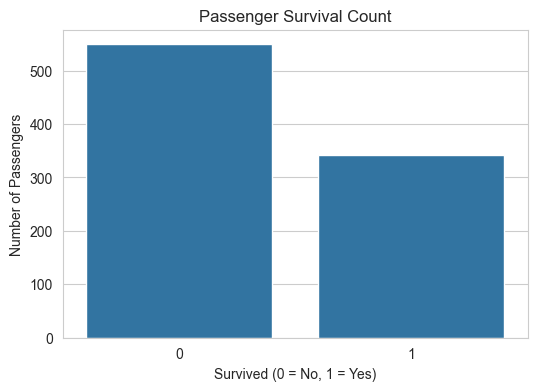

In [42]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Survived")

plt.title("Passenger Survival Count")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.savefig("output/plots/survival_count.png")
plt.show()

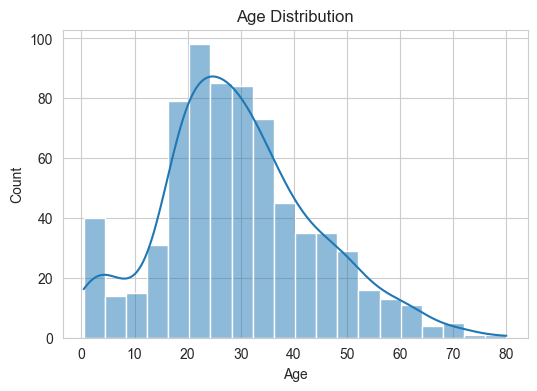

In [43]:
plt.figure(figsize=(6, 4))

sns.histplot(df["Age"], bins=20, kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Count")

plt.savefig("output/plots/age_distribution.png")
plt.show()

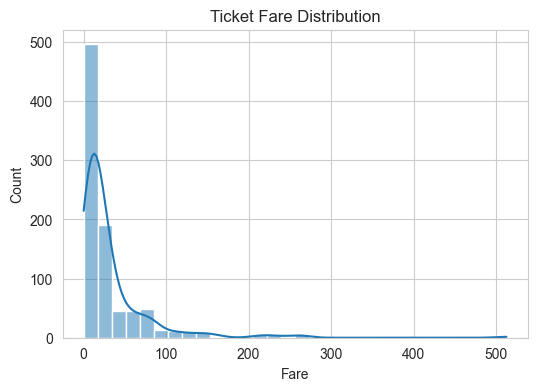

In [44]:
plt.figure(figsize=(6, 4))

sns.histplot(df["Fare"], bins=30, kde=True)

plt.title("Ticket Fare Distribution")
plt.xlabel("Fare")
plt.ylabel("Count")

plt.savefig("output/plots/fare_distribution.png")
plt.show()

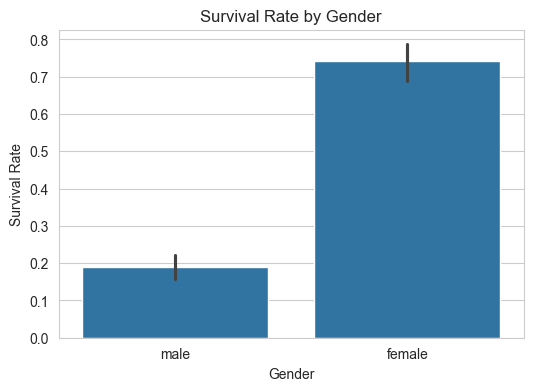

In [45]:
plt.figure(figsize=(6, 4))

sns.barplot(data=df, x="Sex", y="Survived")

plt.title("Survival Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")

plt.savefig("output/plots/gender_survival.png")
plt.show()

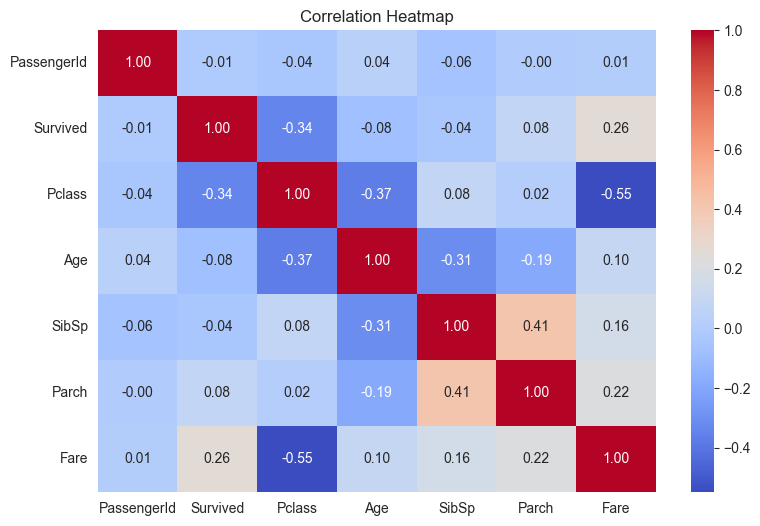

In [46]:
plt.figure(figsize=(9, 6))

sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.savefig("output/plots/correlation_heatmap.png")
plt.show()

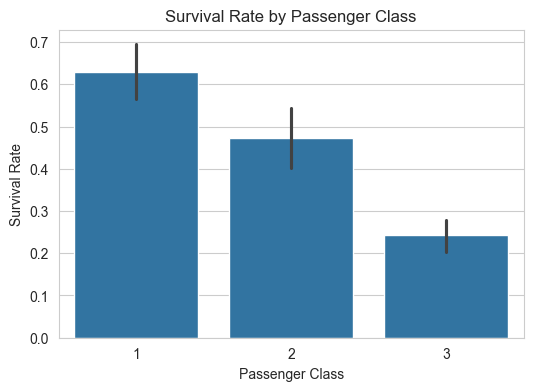

In [47]:
plt.figure(figsize=(6, 4))

sns.barplot(data=df, x="Pclass", y="Survived")

plt.title("Survival Rate by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Survival Rate")

plt.show()

In [48]:
df = df.drop_duplicates()

print("Duplicate rows removed.")
print("New Shape:", df.shape)

Duplicate rows removed.
New Shape: (891, 12)


In [49]:
df["FamilySize"] = df["SibSp"] + df["Parch"] + 1

df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

print("New features created!")

df[["SibSp", "Parch", "FamilySize", "IsAlone"]].head()

New features created!


,SibSp,Parch,FamilySize,IsAlone
0,1,0,2,0
1,1,0,2,0
2,0,0,1,1
3,1,0,2,0
4,0,0,1,1


In [50]:
df.loc[df["Age"] <= 0, "Age"] = np.nan

df.loc[df["Fare"] < 0, "Fare"] = np.nan

print("Invalid values handled.")


Invalid values handled.


In [51]:
df = df.drop(
    columns=["PassengerId", "Name", "Ticket", "Cabin"]
)

print("Unnecessary columns removed.")

df.head()

Unnecessary columns removed.


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone
0,0,3,male,22.0,1,0,7.2500,S,2,0
1,1,1,female,38.0,1,0,71.2833,C,2,0
2,1,3,female,26.0,0,0,7.9250,S,1,1
3,1,1,female,35.0,1,0,53.1000,S,2,0
4,0,3,male,35.0,0,0,8.0500,S,1,1


In [52]:
print("Missing Values After Cleaning:")
print(df.isnull().sum())

Missing Values After Cleaning:
Survived        0
Pclass          0
Sex             0
Age           177
SibSp           0
Parch           0
Fare            0
Embarked        2
FamilySize      0
IsAlone         0
dtype: int64


In [53]:
df.to_csv("output/clean_dataset.csv", index=False)

print("Clean dataset saved successfully!")

Clean dataset saved successfully!


In [54]:
X = df.drop("Survived", axis=1)

y = df["Survived"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (891, 9)
Target Shape: (891,)


In [55]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (712, 9)
Testing Data: (179, 9)


In [56]:
num_cols = X_train.select_dtypes(
    include=["int64", "float64"]
).columns

cat_cols = X_train.select_dtypes(
    include=["object", "category"]
).columns

print("Numerical Columns:", list(num_cols))
print("Categorical Columns:", list(cat_cols))

Numerical Columns: ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize', 'IsAlone']
Categorical Columns: ['Sex', 'Embarked']


C:\Users\X280\AppData\Local\Temp\ipykernel_17720\36621980.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = X_train.select_dtypes(


In [57]:
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

In [58]:
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [59]:
preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

In [60]:
X_train_processed = preprocessor.fit_transform(X_train)

X_test_processed = preprocessor.transform(X_test)

print("Training Data After Processing:", X_train_processed.shape)
print("Testing Data After Processing:", X_test_processed.shape)

Training Data After Processing: (712, 12)
Testing Data After Processing: (179, 12)


In [61]:
# Convert sparse matrix into normal array if needed

if hasattr(X_train_processed, "toarray"):
    X_train_processed = X_train_processed.toarray()

if hasattr(X_test_processed, "toarray"):
    X_test_processed = X_test_processed.toarray()

# Get feature names
feature_names = preprocessor.get_feature_names_out()

# Convert into DataFrames
X_train_final = pd.DataFrame(
    X_train_processed,
    columns=feature_names
)

X_test_final = pd.DataFrame(
    X_test_processed,
    columns=feature_names
)

print("Final Training Data:")
print(X_train_final.head())

print("\nFinal Testing Data:")
print(X_test_final.head())

Final Training Data:
   num__Pclass  num__Age  num__SibSp  num__Parch  num__Fare  num__FamilySize  \
0     0.829568 -0.081135   -0.465084   -0.466183   0.513812        -0.556339   
1    -0.370945 -0.081135   -0.465084   -0.466183  -0.662563        -0.556339   
2    -1.571457 -0.081135   -0.465084   -0.466183   3.955399        -0.556339   
3     0.829568 -0.887827   -0.465084    0.727782  -0.467874         0.073412   
4    -0.370945  0.110934    0.478335    0.727782  -0.115977         0.703162   

   num__IsAlone  cat__Sex_female  cat__Sex_male  cat__Embarked_C  \
0      0.800346              0.0            1.0              0.0   
1      0.800346              0.0            1.0              0.0   
2      0.800346              0.0            1.0              0.0   
3     -1.249460              1.0            0.0              0.0   
4     -1.249460              1.0            0.0              0.0   

   cat__Embarked_Q  cat__Embarked_S  
0              0.0              1.0  
1            

In [62]:
X_train_final.to_csv("output/X_train.csv", index=False)

X_test_final.to_csv("output/X_test.csv", index=False)

y_train.to_csv("output/y_train.csv", index=False)

y_test.to_csv("output/y_test.csv", index=False)

print("All processed datasets saved successfully!")

All processed datasets saved successfully!


In [63]:
joblib.dump(
    preprocessor,
    "output/preprocessing_pipeline.joblib"
)

print("Preprocessing pipeline saved!")

Preprocessing pipeline saved!


In [64]:
loaded_pipeline = joblib.load(
    "output/preprocessing_pipeline.joblib"
)

new_data = X_test.head(5)

new_data_processed = loaded_pipeline.transform(new_data)

print("Pipeline Loaded Successfully!")

print("New Data Shape:", new_data_processed.shape)

Pipeline Loaded Successfully!
New Data Shape: (5, 12)


In [65]:
# Calculate some EDA findings

survival_rate = df["Survived"].mean() * 100

gender_survival = df.groupby("Sex")["Survived"].mean() * 100

class_survival = df.groupby("Pclass")["Survived"].mean() * 100

age_median = df["Age"].median()

# Create README content

readme = f"""
END-TO-END DATA PREPARATION PIPELINE
====================================

1. DATASET INFORMATION
----------------------
Dataset Name: Titanic Dataset
Source: Kaggle
Total Records: {df.shape[0]}
Total Features: {df.shape[1]}

The dataset contains passenger information
such as age, gender, ticket fare and passenger class.

Target Column: Survived
0 = Did not survive
1 = Survived


2. EDA FINDINGS
---------------
Overall Survival Rate: {survival_rate:.2f}%

Survival Rate by Gender:
{gender_survival.to_string()}

Survival Rate by Passenger Class:
{class_survival.to_string()}

Median Passenger Age: {age_median:.2f}

The graphs show the survival distribution,
age distribution, fare distribution and
correlation between numerical features.


3. DATA CLEANING
----------------
- Removed duplicate records.
- Replaced invalid age values with missing values.
- Replaced negative fare values with missing values.
- Removed PassengerId, Name, Ticket and Cabin.
- Created FamilySize feature.
- Created IsAlone feature.


4. PREPROCESSING
----------------
Numerical Features:
- Missing values filled using median.
- StandardScaler applied.

Categorical Features:
- Missing values filled using most frequent value.
- OneHotEncoder applied.

Target Column:
- Survived was separated from input features.


5. TRAIN TEST SPLIT
-------------------
Training Data: 80%
Testing Data: 20%

Random State: 42
Stratified splitting was used.


6. OUTPUT FILES
---------------
- clean_dataset.csv
- X_train.csv
- X_test.csv
- y_train.csv
- y_test.csv
- preprocessing_pipeline.joblib
- plots folder


7. CONCLUSION
-------------
The raw Titanic dataset was cleaned and prepared
for machine learning.

Missing values, categorical features and
numerical features were handled using a
preprocessing pipeline.

The final training and testing datasets
are ready for machine learning models.
"""

with open("output/README.txt", "w") as file:
    file.write(readme)

print("README.txt created successfully!")

README.txt created successfully!


In [66]:
print("FINAL PROJECT OUTPUT")
print("--------------------")

for root, dirs, files in os.walk("output"):
    for file in files:
        print(os.path.join(root, file))

FINAL PROJECT OUTPUT
--------------------
output\clean_dataset.csv
output\preprocessing_pipeline.joblib
output\README.txt
output\X_test.csv
output\X_train.csv
output\y_test.csv
output\y_train.csv
output\plots\age_distribution.png
output\plots\correlation_heatmap.png
output\plots\fare_distribution.png
output\plots\gender_survival.png
output\plots\survival_count.png


In [67]:
print("Project Completed Successfully!")

print("\nClean Dataset:", pd.read_csv(
    "output/clean_dataset.csv"
).shape)

print("Training Data:", pd.read_csv(
    "output/X_train.csv"
).shape)

print("Testing Data:", pd.read_csv(
    "output/X_test.csv"
).shape)

Project Completed Successfully!

Clean Dataset: (891, 10)
Training Data: (712, 12)
Testing Data: (179, 12)
